# Chapter 11 Extras — replication checks and failure modes

Companion to [`ch11_lab.ipynb`](ch11_lab.ipynb) (Parts 1–3 on synthetic data) and [Research 002](../research/002-nifty-cycle-tools/README.md) (Parts 4–5 on NIFTY daily data). This notebook holds only what those two do not cover:

1. the book's copper example, recomputed from Table 11.4;
2. an error in the book's Excel Fourier example;
3. how smoothing **creates** cycles in pure noise (Slutsky–Yule), and the null test that guards against it;
4. a pre-declared cycle test on NIFTY **monthly** returns;
5. the Hilbert transform's missing gain correction, and what it does to Research 002's signals.

Code lives in [`lib/`](../lib/) with tests in `tests/`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent
sys.path.insert(0, str(REPO))       # so `lib` imports without installing the package
from lib.indicators import triangular_macd, hilbert_phase
from lib.cycles import periodogram, top_periods, single_frequency_fit, max_peak_test, turning_point_spacing

rng = np.random.default_rng(11)

## 1. Single-frequency trigonometric regression on the book's copper data (pp. 500–502)

Kaufman's steps:
1. Fit a least-squares line `y = a + bx` and subtract it.
2. `α = Σcd / Σc²`, with `c = y_n` and `d = y_{n−1} + y_{n+1}`.
3. `cos ω = α/2`, so the period is `T = 360°/ω`.
4. Solve the normal equations for `a, b` in `y_t = a cos ωt + b sin ωt`.

Why step 2 works: for a pure sine, `sin(ω(t−1)) + sin(ω(t+1)) = 2 cos ω · sin(ωt)`.

Book's values: trend `28.89 + 0.267x`, `Σc² = 6338.4`, `Σcd = 9282.2`, `α = 1.464`, `ω = 42.9°`, `T = 8.4` quarters.

,intercept,slope,sum_c2,sum_cd,alpha,omega_deg,period
All 68 quarters,28.440,0.286,6192.712,10231.504,1.652,34.301,10.495
First 67 quarters,28.924,0.265,6005.265,9756.699,1.625,35.674,10.091
Book (pp. 501-502),28.890,0.267,6338.400,9282.200,1.464,42.900,8.400


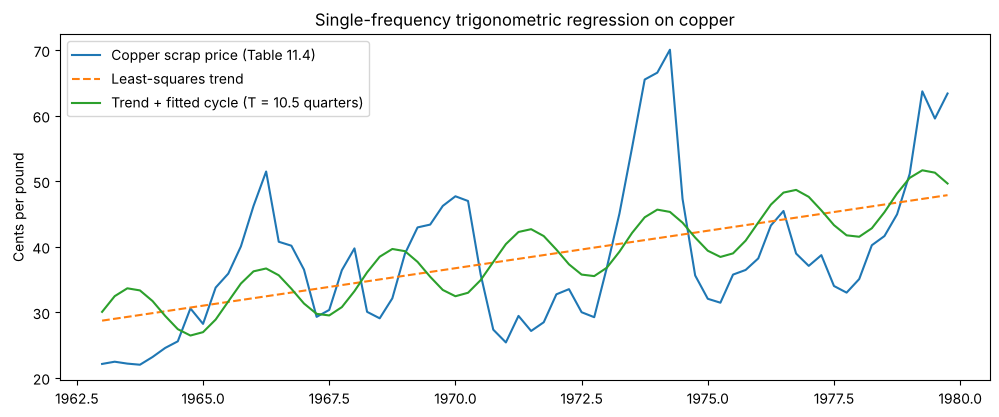

Share of detrended variance explained by the single cycle: 10.1%


In [2]:
copper = pd.read_csv(REPO / 'data' / 'copper_scrap_quarterly_1963_1979.csv')
yq = copper['price_cents_per_lb'].to_numpy()
assert len(yq) == 68

rows = {}
for label, sample in [('All 68 quarters', yq), ('First 67 quarters', yq[:67])]:
    f = single_frequency_fit(sample)
    rows[label] = {k: f[k] for k in ['intercept', 'slope', 'sum_c2', 'sum_cd', 'alpha', 'omega_deg', 'period']}
rows['Book (pp. 501-502)'] = dict(intercept=28.89, slope=0.267, sum_c2=6338.4, sum_cd=9282.2,
                                  alpha=1.464, omega_deg=42.9, period=8.4)
display(pd.DataFrame(rows).T.round(3))

f = single_frequency_fit(yq)
years = copper['year'] + (copper['quarter'] - 1) / 4
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(years, yq, label='Copper scrap price (Table 11.4)')
ax.plot(years, f['trend'], '--', label='Least-squares trend')
ax.plot(years, f['trend'] + f['fitted_cycle'], label=f"Trend + fitted cycle (T = {f['period']:.1f} quarters)")
ax.set(title='Single-frequency trigonometric regression on copper', ylabel='Cents per pound')
ax.legend()
plt.show()
r2 = 1 - ((yq - f['trend'] - f['fitted_cycle'])**2).sum() / ((yq - f['trend'])**2).sum()
print(f'Share of detrended variance explained by the single cycle: {r2:.1%}')

**What replicates and what does not**

- **The trend line replicates.** The first 67 quarters give almost exactly the book's `28.89 + 0.267x`, so the book probably used one quarter less than the table shows.
- **α does not.** No sub-window of the printed table gives the book's `Σc²` and `Σcd`. The data give a period of about **10 quarters**, not 8.4.
- The book also says the copper peaks are "about four years apart" (16 quarters), which matches neither number.

A published cycle period could not be reproduced from the published data. Record it; never tune inputs to force a match.

## 2. Error in the book's Excel Fourier example (pp. 511–513)

The book runs Excel's Fourier analysis on monthly Southwest Airlines and corn returns, takes the first 12 output rows and labels them **Jan to Dec** (Figures 11.16–11.17).

FFT output row `k` is the cycle of length **N/k bars**, not calendar month `k`. With 128 monthly values, row 0 is the average, row 1 a 128-month cycle, row 2 a 64-month cycle, …, row 11 an 11.6-month cycle. Seasonality appears only near a period of 12 months. The cell below plants a single 12-month cycle.

In [3]:
N = 128
months = np.arange(N)
monthly = 1.0 * np.sin(2 * np.pi * months / 12) + rng.normal(0, 0.5, N)
mag = np.abs(np.fft.fft(monthly))
table = pd.DataFrame({'fft_row': np.arange(12),
                      'cycle_length_months': [np.inf] + [N / k for k in range(1, 12)],
                      'book_label': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
                      'IMABS': mag[:12]})
display(table.round(2))
peak_row = int(table.loc[1:, 'IMABS'].idxmax())
label = table.loc[peak_row, 'book_label']
print(f'The planted 12-month cycle peaks at FFT row {peak_row}, i.e. a period of {N / peak_row:.1f} months,')
print(f'which the book\'s labelling would call "{label}". It is one 12-month cycle, not a {label} effect.')

,fft_row,cycle_length_months,book_label,IMABS
0,0,inf,Jan,6.15
1,1,128.00,Feb,5.87
2,2,64.00,Mar,9.17
3,3,42.67,Apr,6.94
4,4,32.00,May,4.76
5,5,25.60,Jun,1.30
6,6,21.33,Jul,2.11
7,7,18.29,Aug,15.59
8,8,16.00,Sep,11.91
9,9,14.22,Oct,12.19


The planted 12-month cycle peaks at FFT row 11, i.e. a period of 11.6 months,
which the book's labelling would call "Dec". It is one 12-month cycle, not a Dec effect.


## 3. Smoothing creates cycles (Slutsky–Yule)

Take a random walk, which has no cycles by construction, and apply a band-pass filter such as Kaufman's triangular MACD. The output looks like a regular cycle. The "cycle" belongs to the **filter**: an MA difference passes a band of periods and suppresses the rest, so it always shows waves in that band.

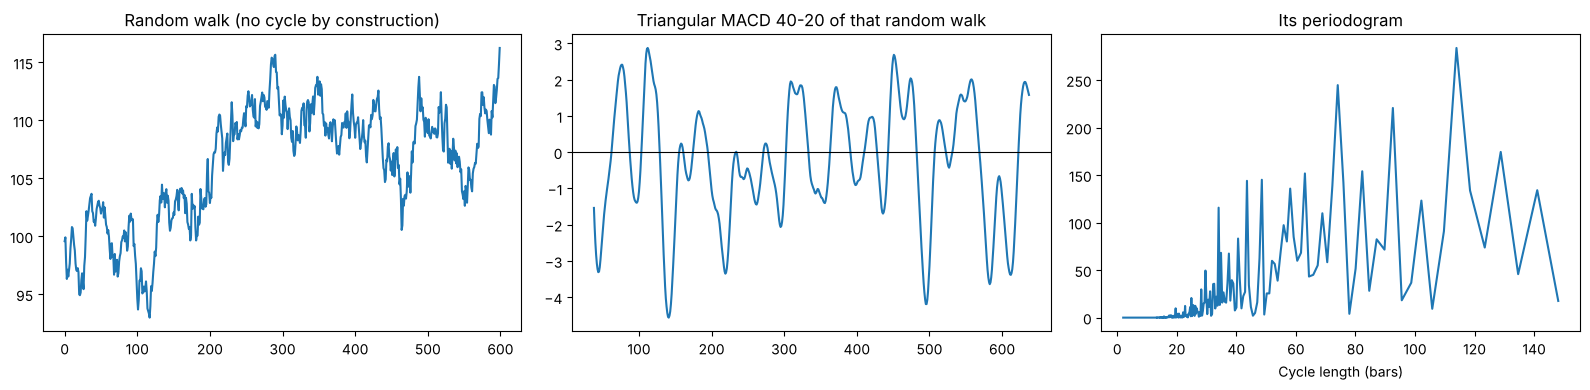

Peak-to-peak spacing of the "cycle": median 30 bars, interquartile range 23-38 bars.
The filter manufactured a regular-looking cycle from noise.


In [4]:
walk = pd.Series(100 + np.cumsum(rng.normal(0, 1, 3000)))
tmacd_walk = triangular_macd(walk, 40).dropna()
spacing = turning_point_spacing(tmacd_walk)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(walk.iloc[:600]); axes[0].set_title('Random walk (no cycle by construction)')
axes[1].plot(tmacd_walk.iloc[:600]); axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Triangular MACD 40-20 of that random walk')
spec_walk = periodogram(tmacd_walk)
s = spec_walk[spec_walk.index <= 150]
axes[2].plot(s.index, s.values); axes[2].set(title='Its periodogram', xlabel='Cycle length (bars)')
plt.tight_layout()
plt.show()

print(f'Peak-to-peak spacing of the "cycle": median {np.median(spacing):.0f} bars, '
      f'interquartile range {np.percentile(spacing, 25):.0f}-{np.percentile(spacing, 75):.0f} bars.')
print('The filter manufactured a regular-looking cycle from noise.')

### Defence: a pre-declared null test

- **statistic:** the largest periodogram value over the band of periods you care about;
- **null:** the same returns shuffled (keeps their distribution, destroys any cycle);
- **p-value:** share of shuffled series with a peak at least as large.

Taking the maximum over the whole band already accounts for searching many periods. Sanity checks: a series with a planted cycle must be detected, and a random walk must not.

In [5]:
t = np.arange(750)
synthetic = pd.Series(100 + 0.03 * t + 2 * np.sin(2 * np.pi * t / 40) + np.sin(2 * np.pi * t / 20)
                      + rng.normal(0, 0.8, len(t)))
_, per, p_synth, _ = max_peak_test(synthetic.diff().dropna(), 4, 120, n_perm=1000)
print(f'Planted 40/20-bar cycles: strongest period {per:.1f} bars, p = {p_synth:.4f}')
_, per, p_walk, _ = max_peak_test(walk.diff().dropna().iloc[:750], 4, 120, n_perm=1000)
print(f'Random walk:              strongest period {per:.1f} bars, p = {p_walk:.3f}')
assert p_synth < 0.01

Planted 40/20-bar cycles: strongest period 39.4 bars, p = 0.0020


Random walk:              strongest period 6.9 bars, p = 0.261


## 4. Is there a cycle in NIFTY monthly returns?

**Pre-declared before running:**
- **data:** NIFTY 50 monthly log returns, longest contiguous run without missing months (2002-02 to 2025-12);
- **H0:** returns contain no periodic structure;
- **statistic:** largest periodogram value for periods of 3–60 months;
- **test:** 5,000 shuffles, seed 1101, reject at 5%;
- no other periods, windows or data choices tried afterwards.

Limitation: shuffling also destroys volatility clustering, so it is a lenient null. A rejection would mean "investigate", not "trade".

287 monthly returns, 2002-02 to 2025-12


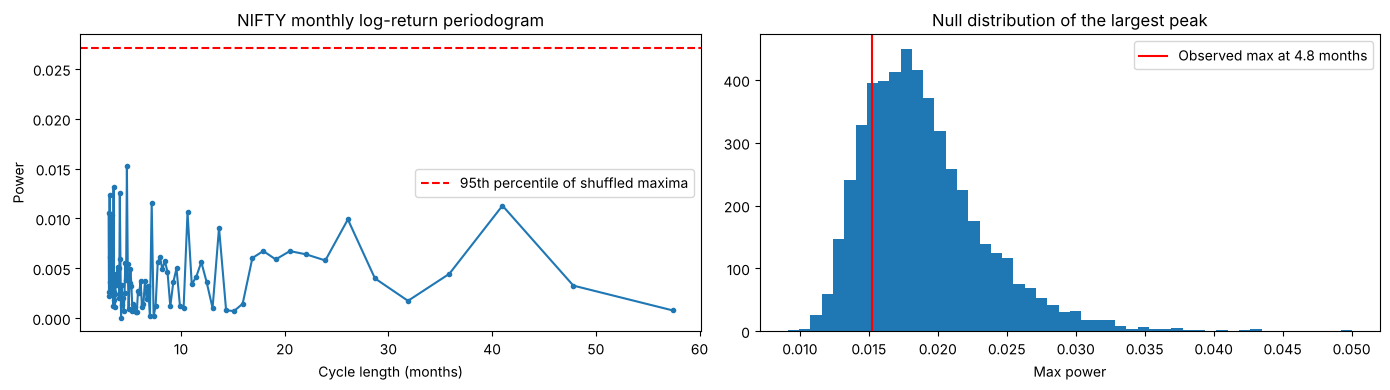

Largest peak: 4.8 months, permutation p = 0.804
Decision: do not reject H0: no evidence of a cycle in this test


In [6]:
nifty = pd.read_csv(REPO / 'data' / 'nifty50_monthly_2000_2026_partial.csv',
                    parse_dates=['month']).set_index('month').sort_index()
nifty = nifty[(nifty.index >= '2002-01-01') & (nifty.index < '2026-01-01')]
code_month = nifty.index.year * 12 + nifty.index.month
assert (np.diff(code_month) == 1).all(), 'Window must be contiguous'
log_ret = np.log(nifty['close']).diff().dropna()
print(f'{len(log_ret)} monthly returns, {log_ret.index[0]:%Y-%m} to {log_ret.index[-1]:%Y-%m}')

obs, per, p_nifty, null = max_peak_test(log_ret, 3, 60, n_perm=5000, seed=1101)
spec_n = periodogram(log_ret)
band = spec_n[(spec_n.index >= 3) & (spec_n.index <= 60)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(band.index, band.values, marker='.')
axes[0].axhline(np.percentile(null, 95), color='red', linestyle='--', label='95th percentile of shuffled maxima')
axes[0].set(title='NIFTY monthly log-return periodogram', xlabel='Cycle length (months)', ylabel='Power')
axes[0].legend()
axes[1].hist(null, bins=50)
axes[1].axvline(obs, color='red', label=f'Observed max at {per:.1f} months')
axes[1].set(title='Null distribution of the largest peak', xlabel='Max power')
axes[1].legend()
plt.tight_layout()
plt.show()

print(f'Largest peak: {per:.1f} months, permutation p = {p_nifty:.3f}')
print('Decision:', 'reject H0 (investigate further)' if p_nifty < 0.05 else 'do not reject H0: no evidence of a cycle in this test')

## 5. The Hilbert transform's missing gain correction

Kaufman (p. 516): `I = P_{t−3}`, `Q = 0.0962·P_t + 0.5769·P_{t−2} − 0.5769·P_{t−4} − 0.0962·P_{t−6}`.

This short filter shifts the phase by exactly 90° but **shrinks Q** at longer periods (to 0.51× at 20 bars). Ehlers multiplies Q by `0.075·Period + 0.54`; the book leaves this out. Without it the phase still completes 360° per cycle, so its *average* step is right, but it advances unevenly within the cycle.

Below: `lib.indicators.hilbert_phase` (with the correction) against Research 002's `cycle_tools.hilbert_phase` (book formula, no correction) on pure sine waves.

In [7]:
sys.path.insert(0, str(REPO / 'research' / '002-nifty-cycle-tools'))
import cycle_tools as ct

rows = []
for P in (10, 14, 20, 30, 40):
    t = np.arange(400)
    x = pd.Series(np.sin(2 * np.pi * t / P))
    corrected = (hilbert_phase(x, P).diff() % 360).iloc[20:]
    book = ct.hilbert_phase(x)
    steps = book['dphase'].iloc[20:]
    # Research 002 signal timing: buy when its phase crosses 90°, sell when it crosses 270°.
    ph = book['phase']; adv = (ph - ph.shift(1)) % 360 < 180
    buys = np.flatnonzero(((ph.shift(1) < 90) & (ph >= 90) & adv).to_numpy()); buys = buys[buys > 20]
    troughs = [k for k in range(21, 399) if x[k] < x[k - 1] and x[k] <= x[k + 1]]
    lag = np.median([b - min(troughs, key=lambda q: abs(q - b)) for b in buys])
    rows.append({'period': P, 'ideal step °': 360 / P,
                 'corrected step min–max °': f'{corrected.min():.1f}–{corrected.max():.1f}',
                 'book step min–max °': f'{steps.min():.1f}–{steps.max():.1f}',
                 'R002 buy signal vs trough (bars)': int(lag)})
display(pd.DataFrame(rows).set_index('period'))

,ideal step °,corrected step min–max °,book step min–max °,R002 buy signal vs trough (bars)
period,,,,
10,36.000000,33.2–39.7,31.3–40.2,1
14,25.714286,23.8–28.0,17.9–35.0,0
20,18.000000,17.3–18.8,9.4–32.4,-1
30,12.000000,11.8–12.2,4.2–31.1,-4
40,9.000000,8.5–9.5,2.4–30.6,-6


**What this means for Research 002:** its "trough passed" buy fires within a bar of the true trough for 10–20 bar cycles, but 4–6 bars **early** for 30–40 bar cycles. NIFTY's cycle-mode episodes implied periods of about 14 days, where the timing is accurate, so the Research 002 conclusion (no edge) is not affected. Any future use of the phase angle should use the corrected version in `lib/`.

In [8]:
assert np.isclose(single_frequency_fit(yq[:67])['slope'], 0.265, atol=0.001)
assert p_synth < 0.01
assert hilbert_phase(np.sin(2 * np.pi * np.arange(300) / 20), 20).diff().mod(360).iloc[20:].between(17, 19).all()
print('Chapter 11 extras sanity checks passed.')

Chapter 11 extras sanity checks passed.


## Reflection

1. Why could the copper cycle period not be reproduced, and what does that say about single-frequency fits?
2. Why doesn't the book's Jan–Dec label on Fourier output mean months of the year?
3. How can a triangular MACD show a regular cycle in a random walk?
4. What null hypothesis did the NIFTY monthly test use, and what are its limits?
5. Why can a phase angle average the right speed and still time turns badly?